# Tier C: FNSPID chunk reader and deduplication

The file is read straight from Hugging Face in pieces of 500,000 rows. Only 4 columns are kept, and the counts are added up piece by piece. Everything is saved to Google Drive.

## 1. Setup

In [1]:
!pip install -q -U huggingface_hub
import os, re
import pandas as pd
from huggingface_hub import HfFileSystem

# Save to Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/fnspid_news'
except Exception:
    BASE = 'fnspid_news'
DATA, RESULTS = BASE + '/data', BASE + '/results'
PARTS = DATA + '/fnspid_parts'
for folder in [DATA, RESULTS, PARTS]:
    os.makedirs(folder, exist_ok=True)
print('Saving to', BASE)

fs = HfFileSystem()
SOURCE = 'datasets/Zihan1004/FNSPID/Stock_news/nasdaq_exteral_data.csv'
KEEP = ['Date', 'Article_title', 'Stock_symbol', 'Publisher']
CHUNK = 500_000

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 9.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
Mounted at /content/drive
Saving to /content/drive/MyDrive/fnspid_news


## 2. Chunk reader with counts

For each piece of 500,000 rows it:
1. keeps the 4 columns and saves them as a small Parquet file,
2. adds to three count tables: rows **per year**, rows **per ticker**, empty values **per column**,
3. also counts rows whose time is exactly `00:00:00` (date only), per year.

If a file called `done.txt` already exists in Drive, this step is skipped.

In [2]:
DONE = PARTS + '/done.txt'

if os.path.exists(DONE):
    print('Already done earlier:', open(DONE).read())
else:
    per_year = pd.Series(dtype='int64')
    per_year_date_only = pd.Series(dtype='int64')
    per_ticker = pd.Series(dtype='int64')
    empty = pd.Series(0, index=KEEP)
    rows = 0

    with fs.open(SOURCE, 'rb') as f:
        reader = pd.read_csv(f, usecols=KEEP, dtype=str, keep_default_na=False, na_values=[''],
                             chunksize=CHUNK, on_bad_lines='skip')
        for i, chunk in enumerate(reader):
            chunk.to_parquet(f'{PARTS}/part_{i:03d}.parquet', index=False)

            year = chunk['Date'].str[:4]
            date_only = chunk['Date'].str[11:19] == '00:00:00'
            per_year = per_year.add(year.value_counts(), fill_value=0)
            per_year_date_only = per_year_date_only.add(year[date_only].value_counts(), fill_value=0)
            per_ticker = per_ticker.add(chunk['Stock_symbol'].value_counts(), fill_value=0)
            empty += chunk.isna().sum()
            rows += len(chunk)
            print(f'piece {i:03d}: {rows:,} rows read')

    year_table = pd.DataFrame({'rows': per_year, 'date_only_rows': per_year_date_only}).fillna(0).astype(int)
    year_table['date_only_pct'] = (year_table['date_only_rows'] / year_table['rows'] * 100).round(1)
    year_table.sort_index().to_csv(RESULTS + '/fnspid_rows_per_year.csv', index_label='year')
    per_ticker.astype(int).sort_values(ascending=False).to_csv(RESULTS + '/fnspid_rows_per_ticker.csv', index_label='ticker', header=['rows'])
    pd.DataFrame({'empty': empty.astype(int), 'empty_pct': (empty / rows * 100).round(2)}).to_csv(
        RESULTS + '/fnspid_empty_per_column.csv', index_label='column')
    open(DONE, 'w').write(f'{rows} rows, {i + 1} pieces')
    print(f'Done: {rows:,} rows in {i + 1} pieces')

Already done earlier: 15549299 rows, 32 pieces


In [3]:
# Show the three count tables
year_table = pd.read_csv(RESULTS + '/fnspid_rows_per_year.csv')
ticker_table = pd.read_csv(RESULTS + '/fnspid_rows_per_ticker.csv')
empty_table = pd.read_csv(RESULTS + '/fnspid_empty_per_column.csv')

print('Rows:', year_table['rows'].sum(), '| tickers:', len(ticker_table))
print('Date-only rows overall:', round(year_table['date_only_rows'].sum() / year_table['rows'].sum() * 100, 1), '%')
display(empty_table)
display(ticker_table.head(10))
year_table

Rows: 15549299 | tickers: 8552
Date-only rows overall: 44.5 %


,column,empty,empty_pct
0,Date,0,0.00
1,Article_title,1,0.00
2,Stock_symbol,9804627,63.06
3,Publisher,11522656,74.10


,ticker,rows
0,GILD,12376
1,NVDA,11862
2,QQQ,11813
3,BABA,11625
4,WFC,11301
5,INTC,11157
6,MRK,10774
7,TSLA,10587
8,KO,10521
9,BROGW,10456


,year,rows,date_only_rows,date_only_pct
0,1914,5,5,100.0
1,1969,1,1,100.0
2,1999,3081,3081,100.0
3,2000,16176,16176,100.0
4,2001,21974,21974,100.0
5,2002,22179,22179,100.0
6,2003,21557,21557,100.0
7,2004,24386,24386,100.0
8,2005,30718,30718,100.0
9,2006,36057,36057,100.0


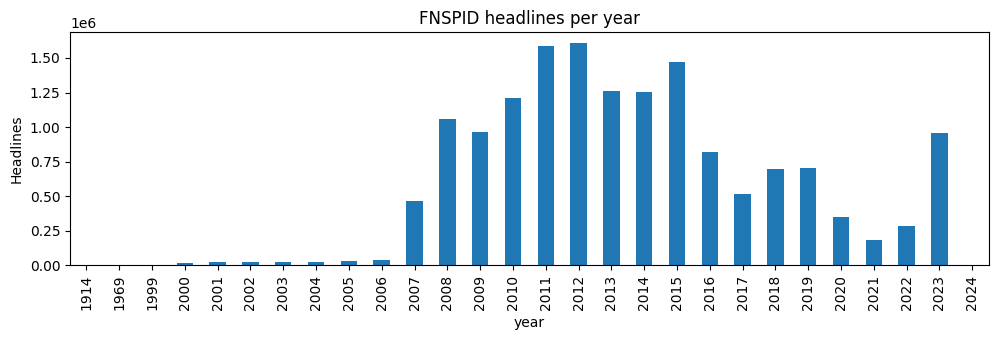

In [4]:
import matplotlib.pyplot as plt
ax = year_table.plot.bar(x='year', y='rows', legend=False, figsize=(10, 3.5), title='FNSPID headlines per year')
ax.set_ylabel('Headlines')
plt.tight_layout()
plt.savefig(RESULTS + '/fnspid_rows_per_year.png', dpi=150)
plt.show()

## 3. Deduplication

Two steps, with the row count recorded after each:

1. **Exact duplicates:** same ticker, same date and time, same headline text.
2. **Near-duplicates per ticker per day:** same ticker, same calendar day, and the same headline after simple cleaning: lower case, punctuation removed, extra spaces removed. This catches the same story repeated with tiny differences, e.g. `Apple Beats Q4 Estimates` and `apple beats Q4 estimates!`. The rule is deliberately strict, so different headlines are never merged by mistake.

The same headline under **different** tickers is not a duplicate: it is kept once per ticker, because each ticker is a separate company.

In [5]:
news = pd.concat([pd.read_parquet(f'{PARTS}/{p}') for p in sorted(os.listdir(PARTS)) if p.endswith('.parquet')],
                 ignore_index=True)
counts = [('1. Read from FNSPID', len(news))]

# Rows that cannot be used at all: no date, no headline or no ticker
news = news.dropna(subset=['Date', 'Article_title', 'Stock_symbol'])
counts.append(('2. After removing rows with no date, headline or ticker', len(news)))

# Step 1: exact duplicates
news = news.drop_duplicates(subset=['Stock_symbol', 'Date', 'Article_title'])
counts.append(('3. After removing exact duplicates', len(news)))

# Step 2: near-duplicates per ticker per day
def clean_title(t):
    t = t.str.lower()
    t = t.str.replace(r'[^a-z0-9 ]', ' ', regex=True)            # punctuation
    return t.str.replace(r'\s+', ' ', regex=True).str.strip()   # extra spaces

news['day'] = news['Date'].str[:10]
news['title_clean'] = clean_title(news['Article_title'])
news = news.drop_duplicates(subset=['Stock_symbol', 'day', 'title_clean'])
counts.append(('4. After removing near-duplicates per ticker per day', len(news)))

dedup = pd.DataFrame(counts, columns=['step', 'rows'])
dedup['removed'] = (-dedup['rows'].diff()).fillna(0).astype(int)
dedup['remaining_pct'] = (dedup['rows'] / dedup['rows'].iloc[0] * 100).round(1)
dedup.to_csv(RESULTS + '/fnspid_dedup_counts.csv', index=False)
dedup

,step,rows,removed,remaining_pct
0,1. Read from FNSPID,15549299,0,100.0
1,"2. After removing rows with no date, headline ...",5744672,9804627,36.9
2,3. After removing exact duplicates,5544523,200149,35.7
3,4. After removing near-duplicates per ticker p...,5541739,2784,35.6


In [6]:
# Look at a few removed near-duplicates to check the rule is sensible
example_day = news.groupby(['Stock_symbol', 'day']).size().idxmax()
print('Busiest ticker-day after dedup:', example_day)

# Save the clean table for the next steps (mapping, trading dates, coverage audit, samples)
news = news.drop(columns='title_clean')
news.to_parquet(DATA + '/fnspid_clean.parquet', index=False)
print('Saved', DATA + '/fnspid_clean.parquet', '|', f'{len(news):,} rows')

Busiest ticker-day after dedup: ('BROGW', '2023-12-16')
Saved /content/drive/MyDrive/fnspid_news/data/fnspid_clean.parquet | 5,541,739 rows
